In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile

# ==========================================
# 1. CONFIGURATION
# ==========================================

INPUT_PATH = Path("../data/processed/transactions_clean.csv")
OUTPUT_DIR = Path("../reports/eda_outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHUNK_SIZE = 250_000

if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"CSV not found: {INPUT_PATH.resolve()}"
    )

USE_COLS = [
    "step",
    "type",
    "amount",
    "isFraud",
    "hour_of_day",
    "simulation_day"
]

# ==========================================
# 2. INITIALIZE AGGREGATION
# ==========================================

total_rows = 0
total_fraud = 0
total_amount = 0.0
total_fraud_amount = 0.0

min_amount = np.inf
max_amount = -np.inf

invalid_labels = 0
negative_amounts = 0

missing_values = {col: 0 for col in USE_COLS}

type_parts = []
hour_parts = []
day_parts = []
amount_parts = []
fraud_amount_parts = []

# ==========================================
# 3. READ CSV IN CHUNKS
# ==========================================

print("Reading CSV dataset...")

for i, chunk in enumerate(
    pd.read_csv(
        INPUT_PATH,
        usecols=USE_COLS,
        chunksize=CHUNK_SIZE
    )
):

    print(f"Processing chunk {i + 1}...")

    total_rows += len(chunk)

    # Data validation
    for col in USE_COLS:
        missing_values[col] += int(
            chunk[col].isna().sum()
        )

    invalid_labels += int(
        (~chunk["isFraud"].isin([0, 1])).sum()
    )

    negative_amounts += int(
        (chunk["amount"] < 0).sum()
    )

    # Overall statistics
    total_fraud += int(chunk["isFraud"].sum())

    total_amount += chunk["amount"].sum()

    fraud_chunk = chunk[
        chunk["isFraud"] == 1
    ]

    total_fraud_amount += fraud_chunk["amount"].sum()

    min_amount = min(
        min_amount,
        chunk["amount"].min()
    )

    max_amount = max(
        max_amount,
        chunk["amount"].max()
    )

    # --------------------------------------
    # Fraud by transaction type
    # --------------------------------------

    type_agg = (
        chunk.groupby("type", observed=True)
        .agg(
            total_transactions=("isFraud", "count"),
            fraud_transactions=("isFraud", "sum"),
            total_amount=("amount", "sum")
        )
        .reset_index()
    )

    type_parts.append(type_agg)

    # --------------------------------------
    # Fraud by hour
    # --------------------------------------

    hour_agg = (
        chunk.groupby("hour_of_day")
        .agg(
            total_transactions=("isFraud", "count"),
            fraud_transactions=("isFraud", "sum")
        )
        .reset_index()
    )

    hour_parts.append(hour_agg)

    # --------------------------------------
    # Fraud by simulation day
    # --------------------------------------

    day_agg = (
        chunk.groupby("simulation_day")
        .agg(
            total_transactions=("isFraud", "count"),
            fraud_transactions=("isFraud", "sum")
        )
        .reset_index()
    )

    day_parts.append(day_agg)

    # --------------------------------------
    # Amount by fraud status
    # --------------------------------------

    amount_agg = (
        chunk.groupby("isFraud")
        .agg(
            transaction_count=("amount", "count"),
            amount_sum=("amount", "sum"),
            amount_min=("amount", "min"),
            amount_max=("amount", "max")
        )
        .reset_index()
    )

    amount_parts.append(amount_agg)

    # --------------------------------------
    # Fraud amount by transaction type
    # --------------------------------------

    if not fraud_chunk.empty:

        fraud_type_agg = (
            fraud_chunk.groupby("type", observed=True)
            .agg(
                fraud_transactions=("amount", "count"),
                total_fraud_amount=("amount", "sum"),
                min_fraud_amount=("amount", "min"),
                max_fraud_amount=("amount", "max")
            )
            .reset_index()
        )

        fraud_amount_parts.append(fraud_type_agg)


print("\nCSV processing completed!")
print("Total Rows:", total_rows)

Reading CSV dataset...
Processing chunk 1...
Processing chunk 2...
Processing chunk 3...
Processing chunk 4...
Processing chunk 5...
Processing chunk 6...
Processing chunk 7...
Processing chunk 8...
Processing chunk 9...
Processing chunk 10...
Processing chunk 11...
Processing chunk 12...
Processing chunk 13...
Processing chunk 14...
Processing chunk 15...
Processing chunk 16...
Processing chunk 17...
Processing chunk 18...
Processing chunk 19...
Processing chunk 20...
Processing chunk 21...
Processing chunk 22...
Processing chunk 23...
Processing chunk 24...
Processing chunk 25...
Processing chunk 26...

CSV processing completed!
Total Rows: 6362620


In [2]:
# ==========================================
# 4. COMBINE AGGREGATED RESULTS
# ==========================================

# Fraud by transaction type

type_summary = (
    pd.concat(type_parts)
    .groupby("type")
    .agg(
        total_transactions=("total_transactions", "sum"),
        fraud_transactions=("fraud_transactions", "sum"),
        total_amount=("total_amount", "sum")
    )
    .reset_index()
)

type_summary["fraud_rate_pct"] = (
    type_summary["fraud_transactions"]
    / type_summary["total_transactions"] * 100
)

type_summary = type_summary.sort_values(
    "fraud_transactions",
    ascending=False
)


# Fraud by hour

hour_summary = (
    pd.concat(hour_parts)
    .groupby("hour_of_day")
    .sum()
    .reset_index()
)

hour_summary = (
    hour_summary.set_index("hour_of_day")
    .reindex(range(24), fill_value=0)
    .rename_axis("hour_of_day")
    .reset_index()
)

hour_summary["fraud_rate_pct"] = (
    hour_summary["fraud_transactions"]
    / hour_summary["total_transactions"].replace(0, np.nan)
    * 100
).fillna(0)


# Fraud by simulation day

day_summary = (
    pd.concat(day_parts)
    .groupby("simulation_day")
    .sum()
    .reset_index()
)

day_summary["fraud_rate_pct"] = (
    day_summary["fraud_transactions"]
    / day_summary["total_transactions"] * 100
)


# Amount by fraud status

amount_summary = (
    pd.concat(amount_parts)
    .groupby("isFraud")
    .agg(
        transaction_count=("transaction_count", "sum"),
        amount_sum=("amount_sum", "sum"),
        amount_min=("amount_min", "min"),
        amount_max=("amount_max", "max")
    )
    .reset_index()
)

amount_summary["average_amount"] = (
    amount_summary["amount_sum"]
    / amount_summary["transaction_count"]
)

amount_summary["transaction_status"] = (
    amount_summary["isFraud"]
    .map({0: "Normal", 1: "Fraud"})
)


# Fraud amount by transaction type

if fraud_amount_parts:

    fraud_amount_summary = (
        pd.concat(fraud_amount_parts)
        .groupby("type")
        .agg(
            fraud_transactions=("fraud_transactions", "sum"),
            total_fraud_amount=("total_fraud_amount", "sum"),
            min_fraud_amount=("min_fraud_amount", "min"),
            max_fraud_amount=("max_fraud_amount", "max")
        )
        .reset_index()
    )

    fraud_amount_summary["average_fraud_amount"] = (
        fraud_amount_summary["total_fraud_amount"]
        / fraud_amount_summary["fraud_transactions"]
    )

else:
    fraud_amount_summary = pd.DataFrame()


# ==========================================
# 5. OVERALL SUMMARY
# ==========================================

overall_summary = pd.DataFrame({
    "metric": [
        "Total Transactions",
        "Fraud Transactions",
        "Normal Transactions",
        "Fraud Rate (%)",
        "Total Transaction Amount",
        "Total Fraud Transaction Amount",
        "Minimum Transaction Amount",
        "Maximum Transaction Amount",
        "Invalid Fraud Labels",
        "Negative Amounts",
        "Total Missing Values"
    ],

    "value": [
        total_rows,
        total_fraud,
        total_rows - total_fraud,
        total_fraud / total_rows * 100 if total_rows else 0,
        total_amount,
        total_fraud_amount,
        min_amount,
        max_amount,
        invalid_labels,
        negative_amounts,
        sum(missing_values.values())
    ]
})


# ==========================================
# 6. SAVE SUMMARY TABLES
# ==========================================

tables = {
    "overall_summary": overall_summary,
    "fraud_by_type": type_summary,
    "fraud_by_hour": hour_summary,
    "fraud_by_day": day_summary,
    "amount_by_fraud_status": amount_summary,
    "fraud_amount_by_type": fraud_amount_summary
}

for name, table in tables.items():

    table.to_csv(
        OUTPUT_DIR / f"{name}.csv",
        index=False
    )


missing_summary = pd.DataFrame(
    list(missing_values.items()),
    columns=["column", "missing_count"]
)

missing_summary.to_csv(
    OUTPUT_DIR / "missing_values.csv",
    index=False
)


# ==========================================
# 7. DISPLAY RESULTS
# ==========================================

print("\n========== OVERALL SUMMARY ==========")
display(overall_summary)

print("\n========== FRAUD BY TYPE ==========")
display(type_summary)

print("\n========== FRAUD BY HOUR ==========")
display(hour_summary)

print("\n========== AMOUNT BY FRAUD STATUS ==========")
display(amount_summary)

print("\n========== FRAUD AMOUNT BY TYPE ==========")
display(fraud_amount_summary)

print("\nEDA aggregation completed!")


========== OVERALL SUMMARY ==========


,metric,value
0,Total Transactions,6.362620e+06
1,Fraud Transactions,8.213000e+03
2,Normal Transactions,6.354407e+06
3,Fraud Rate (%),1.290820e-01
4,Total Transaction Amount,1.144393e+12
5,Total Fraud Transaction Amount,1.205642e+10
6,Minimum Transaction Amount,0.000000e+00
7,Maximum Transaction Amount,9.244552e+07
8,Invalid Fraud Labels,0.000000e+00
9,Negative Amounts,0.000000e+00



========== FRAUD BY TYPE ==========


,type,total_transactions,fraud_transactions,total_amount,fraud_rate_pct
1,CASH_OUT,2237500,4116,3.944130e+11,0.183955
4,TRANSFER,532909,4097,4.852920e+11,0.768799
0,CASH_IN,1399284,0,2.363674e+11,0.000000
2,DEBIT,41432,0,2.271992e+08,0.000000
3,PAYMENT,2151495,0,2.809337e+10,0.000000



========== FRAUD BY HOUR ==========


,hour_of_day,total_transactions,fraud_transactions,fraud_rate_pct
0,0,27111,358,1.320497
1,1,9018,372,4.125083
2,2,2007,326,16.243149
3,3,1241,274,22.078969
4,4,1641,366,22.303473
5,5,3420,358,10.467836
6,6,8988,328,3.649310
7,7,26915,368,1.367267
8,8,283518,341,0.120275
9,9,425729,375,0.088084



========== AMOUNT BY FRAUD STATUS ==========


,isFraud,transaction_count,amount_sum,amount_min,amount_max,average_amount,transaction_status
0,0,6354407,1.132337e+12,0.01,92445516.64,1.781970e+05,Normal
1,1,8213,1.205642e+10,0.00,10000000.00,1.467967e+06,Fraud



========== FRAUD AMOUNT BY TYPE ==========


,type,fraud_transactions,total_fraud_amount,min_fraud_amount,max_fraud_amount,average_fraud_amount
0,CASH_OUT,4116,5.989202e+09,0.0,10000000.0,1.455103e+06
1,TRANSFER,4097,6.067213e+09,63.8,10000000.0,1.480892e+06



EDA aggregation completed!


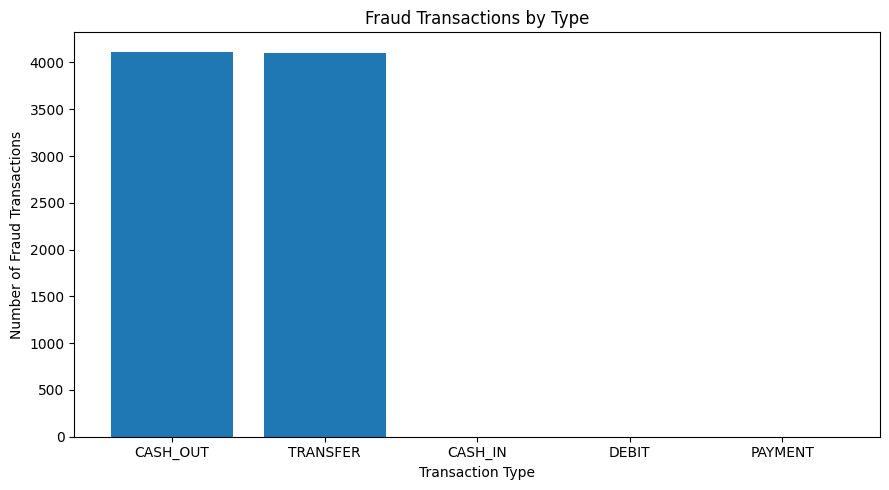

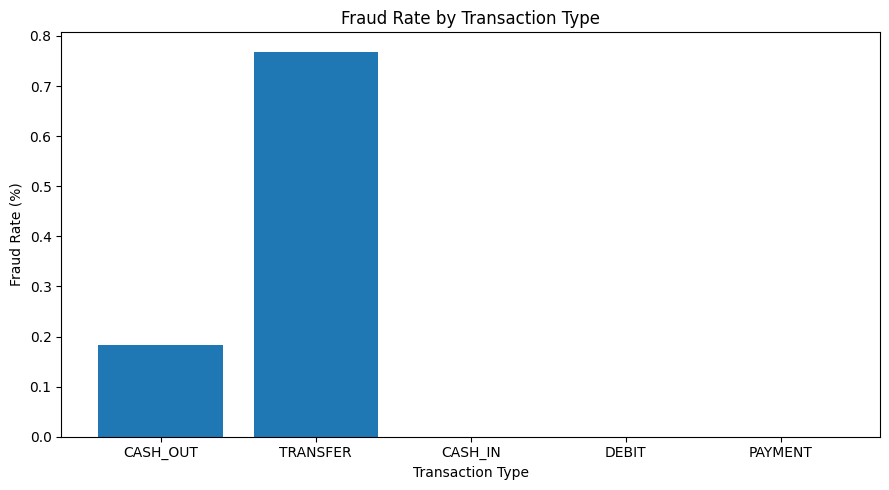

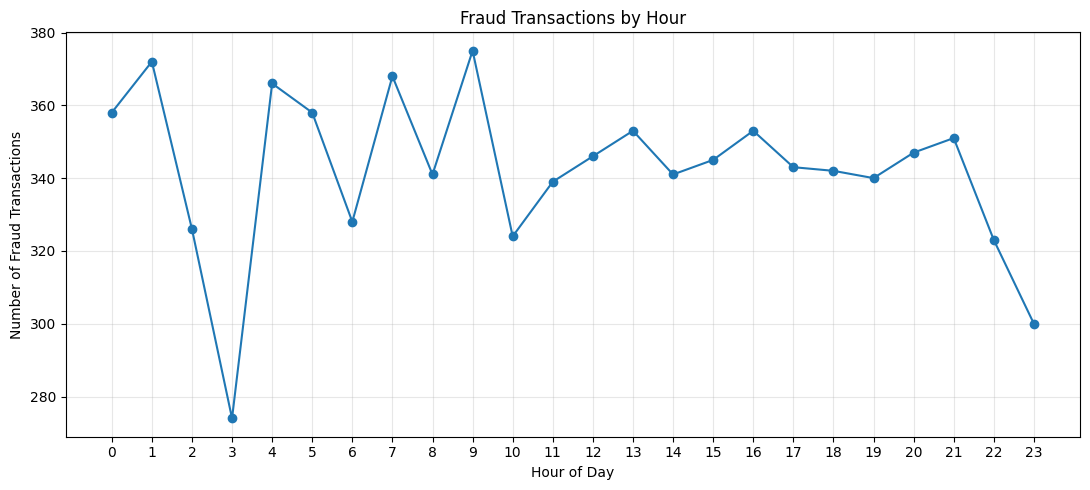

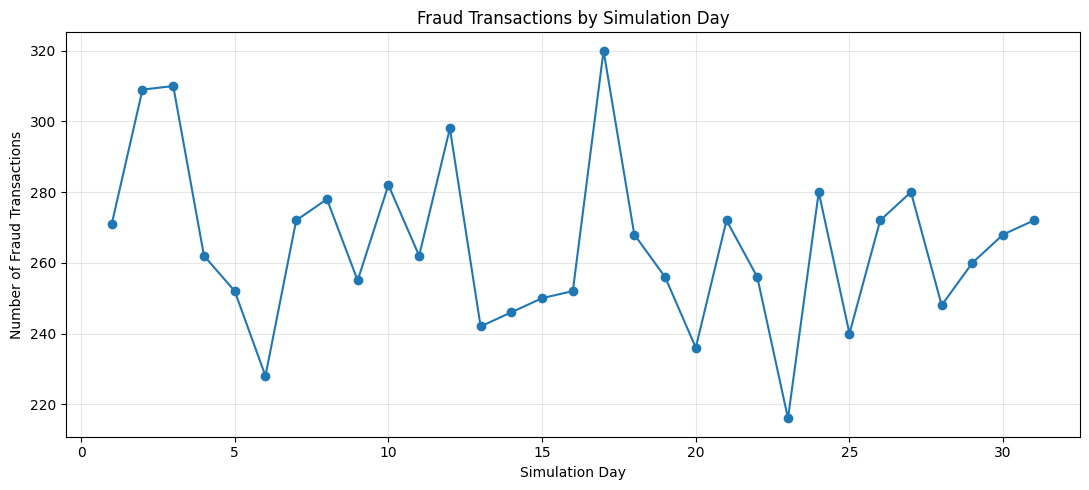

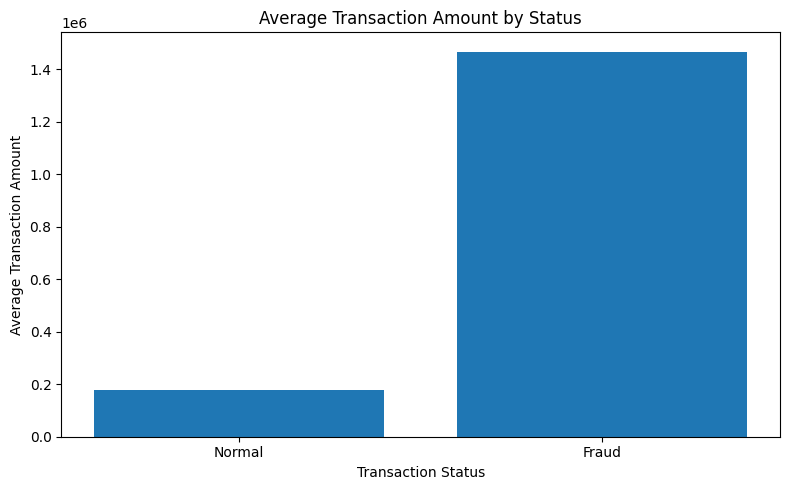

All visualizations saved successfully!


In [3]:
# ==========================================
# 8. VISUALIZATION
# ==========================================

# 1. Fraud transactions by type

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    type_summary["type"].astype(str),
    type_summary["fraud_transactions"]
)

ax.set_title("Fraud Transactions by Type")
ax.set_xlabel("Transaction Type")
ax.set_ylabel("Number of Fraud Transactions")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_fraud_by_type.png", dpi=150)
plt.show()
plt.close()


# 2. Fraud rate by type

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    type_summary["type"].astype(str),
    type_summary["fraud_rate_pct"]
)

ax.set_title("Fraud Rate by Transaction Type")
ax.set_xlabel("Transaction Type")
ax.set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_fraud_rate_by_type.png", dpi=150)
plt.show()
plt.close()


# 3. Fraud transactions by hour

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    hour_summary["hour_of_day"],
    hour_summary["fraud_transactions"],
    marker="o"
)

ax.set_title("Fraud Transactions by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Fraud Transactions")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_fraud_by_hour.png", dpi=150)
plt.show()
plt.close()


# 4. Fraud transactions by simulation day

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    day_summary["simulation_day"],
    day_summary["fraud_transactions"],
    marker="o"
)

ax.set_title("Fraud Transactions by Simulation Day")
ax.set_xlabel("Simulation Day")
ax.set_ylabel("Number of Fraud Transactions")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_fraud_by_day.png", dpi=150)
plt.show()
plt.close()


# 5. Average amount: Fraud vs Normal

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    amount_summary["transaction_status"],
    amount_summary["average_amount"]
)

ax.set_title("Average Transaction Amount by Status")
ax.set_xlabel("Transaction Status")
ax.set_ylabel("Average Transaction Amount")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_average_amount.png", dpi=150)
plt.show()
plt.close()


print("All visualizations saved successfully!")


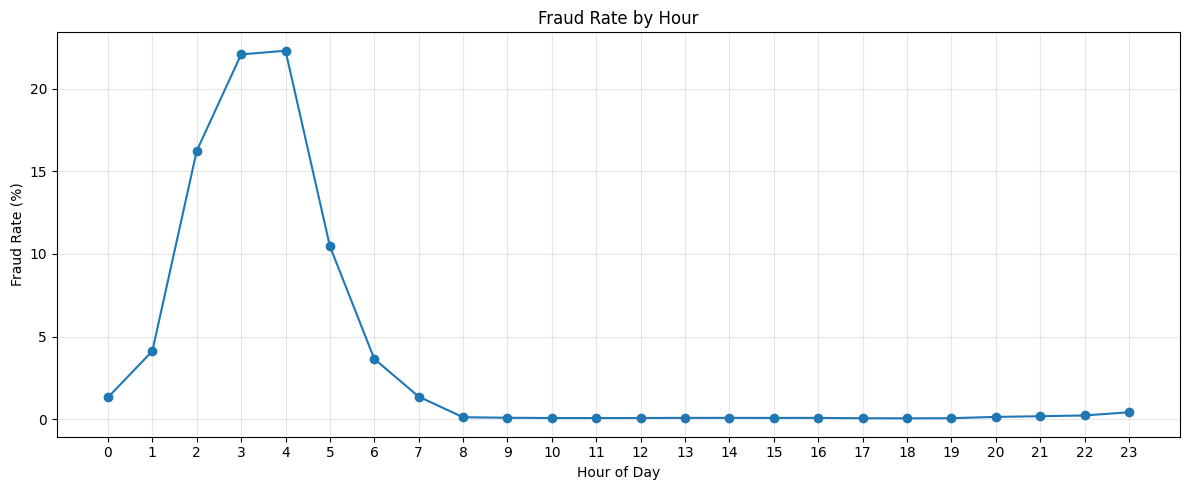

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    hour_summary["hour_of_day"],
    hour_summary["fraud_rate_pct"],
    marker="o"
)

ax.set_title("Fraud Rate by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Fraud Rate (%)")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "06_fraud_rate_by_hour.png",
    dpi=150
)
plt.show()

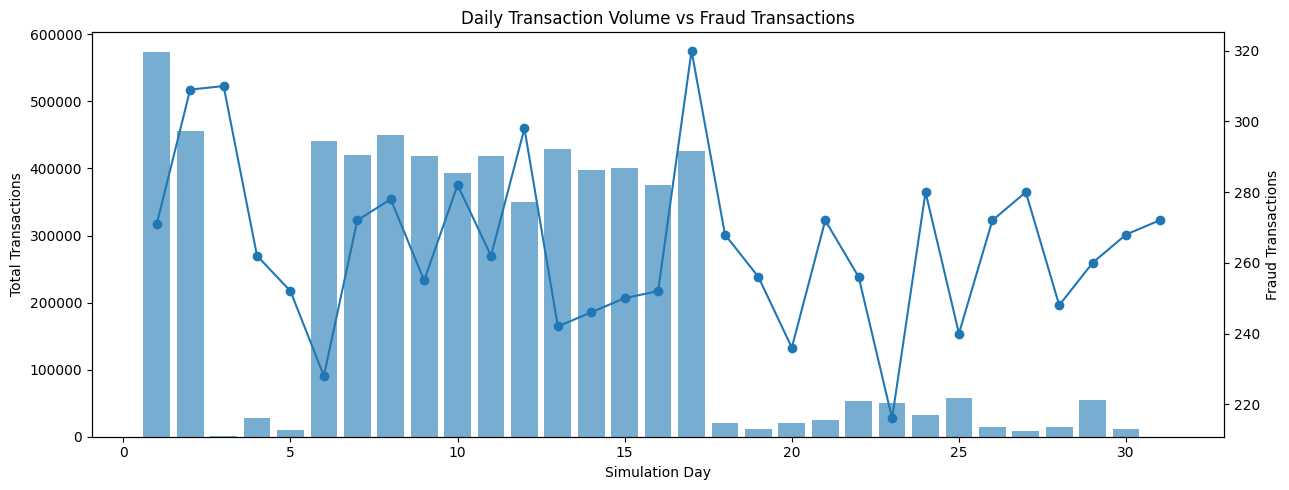

In [5]:
fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.bar(
    day_summary["simulation_day"],
    day_summary["total_transactions"],
    alpha=0.6
)

ax1.set_xlabel("Simulation Day")
ax1.set_ylabel("Total Transactions")

ax2 = ax1.twinx()

ax2.plot(
    day_summary["simulation_day"],
    day_summary["fraud_transactions"],
    marker="o"
)

ax2.set_ylabel("Fraud Transactions")

plt.title("Daily Transaction Volume vs Fraud Transactions")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "07_daily_volume_vs_fraud.png",
    dpi=150
)

plt.show()

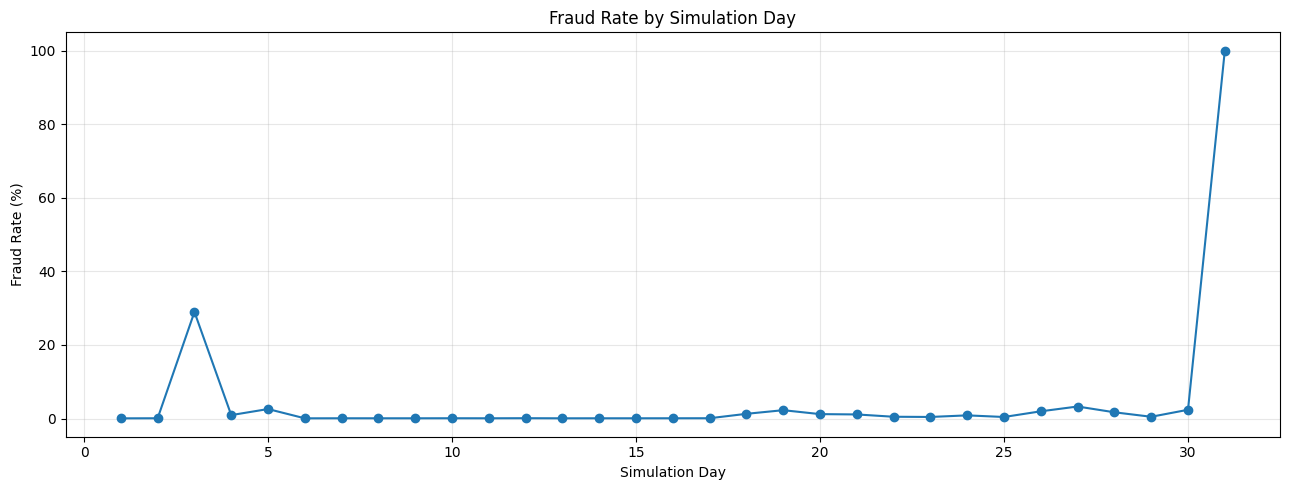

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    day_summary["simulation_day"],
    day_summary["fraud_rate_pct"],
    marker="o"
)

ax.set_title("Fraud Rate by Simulation Day")
ax.set_xlabel("Simulation Day")
ax.set_ylabel("Fraud Rate (%)")
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "08_fraud_rate_by_day.png",
    dpi=150
)

plt.show()

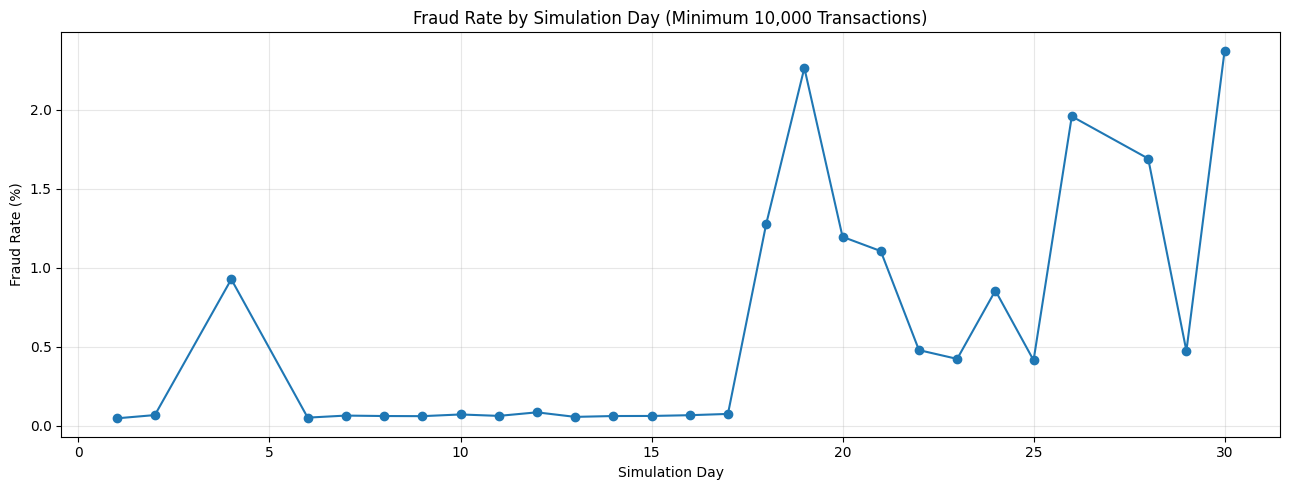

Low-volume days requiring further investigation:


,simulation_day,total_transactions,fraud_transactions,fraud_rate_pct
2,3,1070,310,28.971963
4,5,9789,252,2.574318
26,27,8578,280,3.264164
30,31,272,272,100.000000


In [7]:
# Minimum transaction volume for trend comparison
MIN_TRANSACTIONS = 10_000

stable_days = day_summary[
    day_summary["total_transactions"] >= MIN_TRANSACTIONS
].copy()

low_volume_days = day_summary[
    day_summary["total_transactions"] < MIN_TRANSACTIONS
].copy()

# Plot fraud rate for days with sufficient volume
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    stable_days["simulation_day"],
    stable_days["fraud_rate_pct"],
    marker="o"
)

ax.set_title(
    "Fraud Rate by Simulation Day "
    "(Minimum 10,000 Transactions)"
)

ax.set_xlabel("Simulation Day")
ax.set_ylabel("Fraud Rate (%)")

ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "09_fraud_rate_stable_days.png",
    dpi=150
)

plt.show()

# Show excluded low-volume days separately
print("Low-volume days requiring further investigation:")

display(
    low_volume_days[
        [
            "simulation_day",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate_pct"
        ]
    ]
)

In [8]:
import pandas as pd

csv_path = "../data/processed/transactions_clean.csv"

columns = pd.read_csv(
    csv_path,
    nrows=0
).columns.tolist()

print("Total Columns:", len(columns))

for i, column in enumerate(columns, start=1):
    print(i, column)

Total Columns: 15
1 step
2 type
3 amount
4 nameOrig
5 oldbalanceOrg
6 newbalanceOrig
7 nameDest
8 oldbalanceDest
9 newbalanceDest
10 isFraud
11 isFlaggedFraud
12 hour_of_day
13 simulation_day
14 is_transfer_or_cashout
15 amount_log
